In [2]:

!git clone https://github.com/Krishnalund/CivicFix.git


Cloning into 'CivicFix'...
remote: Enumerating objects: 105, done.
remote: Counting objects: 100% (105/105), done.
remote: Compressing objects: 100% (100/100), done.
remote: Total 105 (delta 7), reused 99 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (105/105), 9.82 MiB | 16.90 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [3]:
%cd CivicFix
!git fetch origin
!git switch --track origin/subhash-work
!git branch --show-current


/content/CivicFix
branch 'subhash-work' set up to track 'origin/subhash-work'.
Switched to a new branch 'subhash-work'
subhash-work


In [4]:

!ls -R


.:
notebooks  README.md  requirements.txt

./notebooks:
01_data_extraction.ipynb    03_model_training.ipynb
02_data_cleaning_EDA.ipynb  04_model_evaluation.ipynb


In [5]:

!git fetch origin model-development
!git ls-tree -r --name-only origin/model-development


From https://github.com/Krishnalund/CivicFix
 * branch            model-development -> FETCH_HEAD
.gitignore
README.md
data/processed/monthly_sampling_plan.csv
data/processed/nyc_311_2020_2025.csv
data/processed/nyc_311_cleaned.csv
data/raw/nyc_311_2020_01.csv
data/raw/nyc_311_2020_02.csv
data/raw/nyc_311_2020_03.csv
data/raw/nyc_311_2020_04.csv
data/raw/nyc_311_2020_05.csv
data/raw/nyc_311_2020_06.csv
data/raw/nyc_311_2020_07.csv
data/raw/nyc_311_2020_08.csv
data/raw/nyc_311_2020_09.csv
data/raw/nyc_311_2020_10.csv
data/raw/nyc_311_2020_11.csv
data/raw/nyc_311_2020_12.csv
data/raw/nyc_311_2021_01.csv
data/raw/nyc_311_2021_02.csv
data/raw/nyc_311_2021_03.csv
data/raw/nyc_311_2021_04.csv
data/raw/nyc_311_2021_05.csv
data/raw/nyc_311_2021_06.csv
data/raw/nyc_311_2021_07.csv
data/raw/nyc_311_2021_08.csv
data/raw/nyc_311_2021_09.csv
data/raw/nyc_311_2021_10.csv
data/raw/nyc_311_2021_11.csv
data/raw/nyc_311_2021_12.csv
data/raw/nyc_311_2022_01.csv
data/raw/nyc_311_2022_02.csv
data/raw/nyc_3

In [6]:

!mkdir -p /content/civicfix_assets/models

!git show origin/model-development:data/processed/nyc_311_cleaned.csv > /content/civicfix_assets/nyc_311_cleaned.csv

!git show origin/model-development:models/logistic_regression.pkl > /content/civicfix_assets/models/logistic_regression.pkl

!git show origin/model-development:models/random_forest.pkl > /content/civicfix_assets/models/random_forest.pkl

!git show origin/model-development:models/gradient_boosting.pkl > /content/civicfix_assets/models/gradient_boosting.pkl


In [7]:

import os

for root, dirs, files in os.walk("/content/civicfix_assets"):
    for file in files:
        path = os.path.join(root, file)
        print(file, ":", round(os.path.getsize(path) / 1024, 2), "KB")


nyc_311_cleaned.csv : 2075.51 KB
logistic_regression.pkl : 33.28 KB
random_forest.pkl : 42392.43 KB
gradient_boosting.pkl : 207.6 KB


In [8]:

import pandas as pd

# Load cleaned dataset
df = pd.read_csv("/content/civicfix_assets/nyc_311_cleaned.csv")

# Display first 5 rows
print("FIRST 5 ROWS:")
display(df.head())

# Dataset shape
print("\nDATASET SHAPE:")
print(df.shape)

# Column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Data types and missing values
print("\nDATASET INFORMATION:")
df.info()

print("\nMISSING VALUES:")
print(df.isnull().sum())


FIRST 5 ROWS:


,agency,complaint_type,descriptor,incident_zip,borough,location_type,target,created_month,created_weekday,created_hour,split_date
0,DOT,Broken Parking Meter,Out of Order,11223,BROOKLYN,Sidewalk,1,1,Friday,15,2020-01-03 15:41:31
1,HPD,SAFETY,SMOKE DETECTOR,11213,BROOKLYN,RESIDENTIAL BUILDING,1,1,Friday,15,2020-01-03 15:41:47
2,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,10014,MANHATTAN,Sidewalk,0,1,Friday,15,2020-01-03 15:42:00
3,DPR,Root/Sewer/Sidewalk Condition,Trees and Sidewalks Program,11210,BROOKLYN,Street,1,1,Friday,15,2020-01-03 15:42:05
4,DOT,Broken Parking Meter,Coin or Card Did Not Register,11222,BROOKLYN,Sidewalk,1,1,Friday,15,2020-01-03 15:42:10



DATASET SHAPE:
(20000, 11)

COLUMN NAMES:
['agency', 'complaint_type', 'descriptor', 'incident_zip', 'borough', 'location_type', 'target', 'created_month', 'created_weekday', 'created_hour', 'split_date']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   agency           20000 non-null  object
 1   complaint_type   20000 non-null  object
 2   descriptor       20000 non-null  object
 3   incident_zip     20000 non-null  object
 4   borough          20000 non-null  object
 5   location_type    20000 non-null  object
 6   target           20000 non-null  int64 
 7   created_month    20000 non-null  int64 
 8   created_weekday  20000 non-null  object
 9   created_hour     20000 non-null  int64 
 10  split_date       20000 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.7+ MB

MISSING VALUES:
agency     

TARGET CLASS DISTRIBUTION
target
0    16330
1     3670
Name: count, dtype: int64

TARGET CLASS PERCENTAGE
target
0    81.65
1    18.35
Name: proportion, dtype: float64


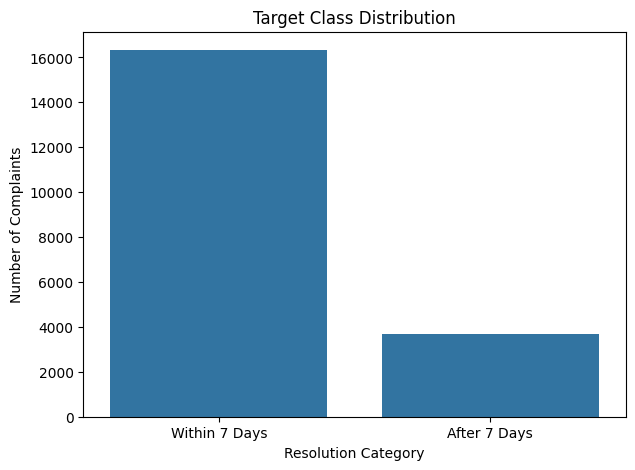

In [9]:

# Count each target class
print("TARGET CLASS DISTRIBUTION")

print(df["target"].value_counts().sort_index())

# Calculate percentages
print("\nTARGET CLASS PERCENTAGE")

print(
    df["target"].value_counts(normalize=True)
    .sort_index() * 100
)

# Visualize class distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="target")

plt.title("Target Class Distribution")
plt.xlabel("Resolution Category")
plt.ylabel("Number of Complaints")
plt.xticks([0, 1], ["Within 7 Days", "After 7 Days"])

plt.show()


In [10]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate target variable
y = df["target"]

# Create majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

# Fit baseline
baseline.fit(df.drop(columns=["target"]), y)

# Predict
baseline_predictions = baseline.predict(df.drop(columns=["target"]))

# Evaluate
print("MAJORITY CLASS BASELINE")
print("Accuracy:", accuracy_score(y, baseline_predictions))

print("\nClassification Report:")
print(classification_report(y, baseline_predictions, zero_division=0))


MAJORITY CLASS BASELINE
Accuracy: 0.8165

Classification Report:
              precision    recall  f1-score   support

           0       0.82      1.00      0.90     16330
           1       0.00      0.00      0.00      3670

    accuracy                           0.82     20000
   macro avg       0.41      0.50      0.45     20000
weighted avg       0.67      0.82      0.73     20000



In [11]:

print("SPLIT DATE DISTRIBUTION:")
print(df["split_date"].value_counts())

print("\nTARGET DISTRIBUTION:")
print(df["target"].value_counts())


SPLIT DATE DISTRIBUTION:
split_date
2020-09-08 12:00:00    21
2021-04-02 13:01:54     7
2021-01-13 11:56:50     6
2024-02-28 23:39:28     5
2023-07-10 08:38:50     5
                       ..
2022-03-30 13:01:30     1
2022-03-30 13:01:00     1
2022-03-30 13:00:29     1
2022-03-30 12:57:52     1
2022-03-30 13:09:00     1
Name: count, Length: 19030, dtype: int64

TARGET DISTRIBUTION:
target
0    16330
1     3670
Name: count, dtype: int64


In [12]:

!git show origin/model-development:notebooks/03_model_training.ipynb | wc -c


30938


In [13]:

import subprocess
import json

# Read Sneha's notebook from her branch
raw = subprocess.check_output(
    ["git", "show", "origin/model-development:notebooks/03_model_training.ipynb"],
    text=True
)

notebook = json.loads(raw)

print("Total cells:", len(notebook["cells"]))

for i, cell in enumerate(notebook["cells"]):
    print("\n" + "="*60)
    print("CELL:", i, "| TYPE:", cell["cell_type"])
    print("="*60)

    source = "".join(cell["source"])
    print(source)

Total cells: 31

CELL: 0 | TYPE: code
import os

print("Current Working Directory:")
print(os.getcwd())

dataset_path = "../data/processed/nyc_311_cleaned.csv"

if os.path.exists(dataset_path):
    print("\nDataset found successfully!")
else:
    print("\nDataset not found!")


CELL: 1 | TYPE: code
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

CELL: 2 | TYPE: code
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

CELL: 3 | TYPE: code
df.head()
print("Dataset Columns:")
for column in df.columns:
    print(column)
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())
print("Target Distribution:")
print(df['target'].value_counts())

print("\nTarget Distribution (%):")
print((df['target'].value_counts(normalize=True) * 100).round(2))

CELL: 4 | TYPE: code
df['split_date'] = pd.to_datetime(df['split_date'], e

In [14]:

import pandas as pd
import numpy as np

# Reload cleaned dataset
eval_df = pd.read_csv(
    "/content/civicfix_assets/nyc_311_cleaned.csv"
)

# Convert split_date into datetime
eval_df["split_date"] = pd.to_datetime(
    eval_df["split_date"],
    errors="coerce"
)

# Sort records by date
eval_df = eval_df.sort_values(
    "split_date"
).reset_index(drop=True)

# Same split as Sneha
train_df = eval_df.iloc[:16000].copy()
test_df = eval_df.iloc[16000:].copy()

# Features used by Sneha
feature_columns = [
    "agency",
    "complaint_type",
    "descriptor",
    "incident_zip",
    "borough",
    "location_type",
    "created_month",
    "created_weekday",
    "created_hour"
]

# Prepare testing features and labels
X_test = test_df[feature_columns].copy()
y_test = test_df["target"].copy()

# Display results
print("TEST DATA PREPARATION")
print("---------------------")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTesting features shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nTesting date range:")
print(test_df["split_date"].min())
print("to")
print(test_df["split_date"].max())


TEST DATA PREPARATION
---------------------
Training records: 16000
Testing records: 4000

Testing features shape: (4000, 9)
Testing target shape: (4000,)

Testing target distribution:
target
0    3386
1     614
Name: count, dtype: int64

Testing date range:
2024-12-03 12:33:57
to
2025-12-23 09:29:32


In [15]:

import joblib

# Load trained models
logistic_model = joblib.load(
    "/content/civicfix_assets/models/logistic_regression.pkl"
)

random_forest_model = joblib.load(
    "/content/civicfix_assets/models/random_forest.pkl"
)

gradient_boosting_model = joblib.load(
    "/content/civicfix_assets/models/gradient_boosting.pkl"
)

print("All three trained models loaded successfully!")

print("\nLogistic Regression:", type(logistic_model))
print("Random Forest:", type(random_forest_model))
print("Gradient Boosting:", type(gradient_boosting_model))



/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid 

All three trained models loaded successfully!

Logistic Regression: <class 'sklearn.pipeline.Pipeline'>
Random Forest: <class 'sklearn.pipeline.Pipeline'>
Gradient Boosting: <class 'sklearn.pipeline.Pipeline'>


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GradientBoostingClassifier from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Store all three models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

# Store evaluation results
results = []

# Evaluate each model
for name, model in models.items():

    print("\n" + "="*50)
    print(name)
    print("="*50)

    # Generate predictions
    predictions = model.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    # Save results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

# Display comparison table
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))



Logistic Regression
Accuracy: 0.854
Precision: 0.5139
Recall: 0.9007
F1-Score: 0.6544

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.85      0.91      3386
           1       0.51      0.90      0.65       614

    accuracy                           0.85      4000
   macro avg       0.75      0.87      0.78      4000
weighted avg       0.91      0.85      0.87      4000


Random Forest
Accuracy: 0.8888
Precision: 0.6256
Recall: 0.6857
F1-Score: 0.6542

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      3386
           1       0.63      0.69      0.65       614

    accuracy                           0.89      4000
   macro avg       0.78      0.81      0.79      4000
weighted avg       0.89      0.89      0.89      4000


Gradient Boosting
Accuracy: 0.8878
Precision: 0.6087
Recall: 0.7524
F1-Score: 0.673

Classification Report:
              precis

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8540,0.5139,0.9007,0.6544
1,Random Forest,0.8888,0.6256,0.6857,0.6542
2,Gradient Boosting,0.8878,0.6087,0.7524,0.6730



 Logistic Regression
[[2863  523]
 [  61  553]]


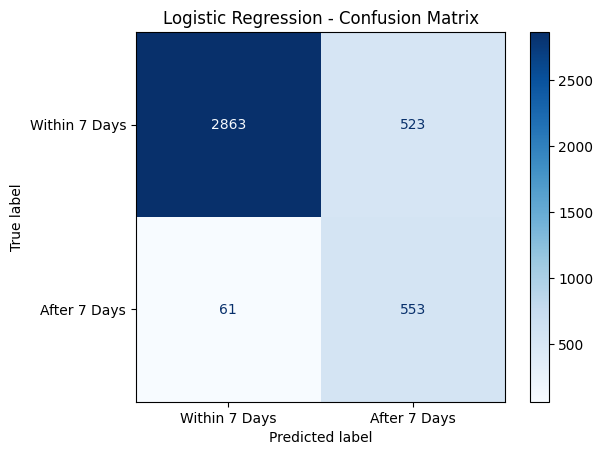


 Random Forest
[[3134  252]
 [ 193  421]]


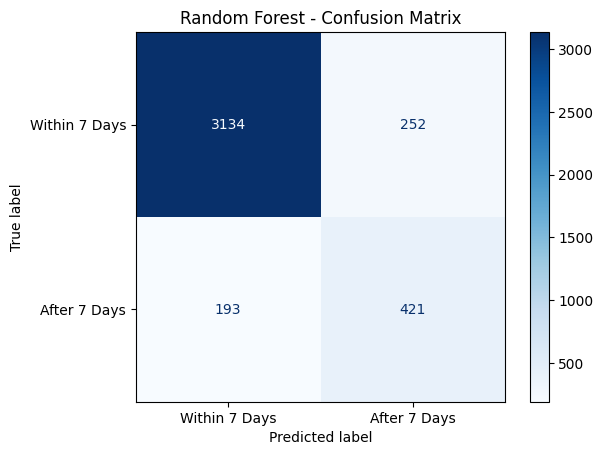


 Gradient Boosting
[[3089  297]
 [ 152  462]]


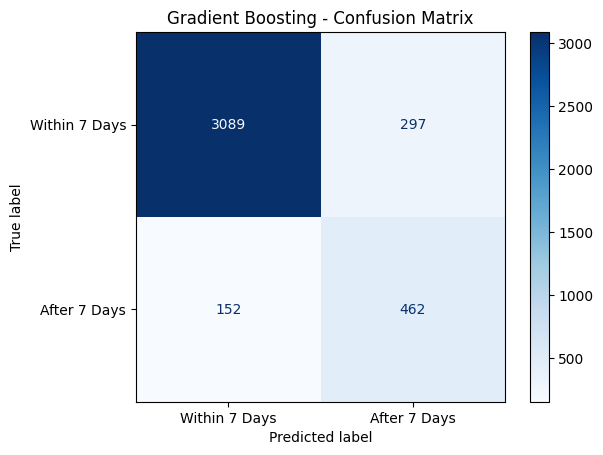

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    print("\n", name)
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Within 7 Days", "After 7 Days"]
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(name + " - Confusion Matrix")
    plt.show()


In [20]:

import pandas as pd
from sklearn.metrics import confusion_matrix

error_analysis = []

for name, model in models.items():

    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    error_analysis.append({
        "Model": name,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

error_df = pd.DataFrame(error_analysis)

print("FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS")
print(error_df.to_string(index=False))


FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS
              Model  False Positives  False Negatives  True Positives  True Negatives
Logistic Regression              523               61             553            2863
      Random Forest              252              193             421            3134
  Gradient Boosting              297              152             462            3089


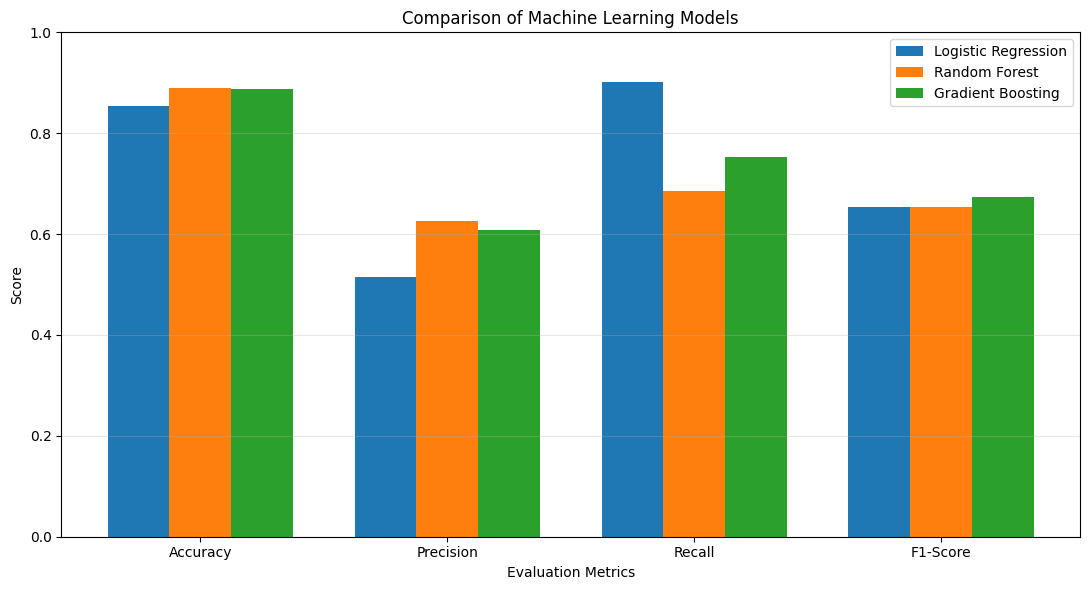

In [21]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(11, 6))

for i, row in results_df.iterrows():
    values = [
        row["Accuracy"],
        row["Precision"],
        row["Recall"],
        row["F1-Score"]
    ]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Model"]
    )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Comparison of Machine Learning Models")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Model Evaluation and Comparison

Three machine learning models were evaluated using the same 4,000 testing records: Logistic Regression, Random Forest, and Gradient Boosting.

The models were evaluated using accuracy, precision, recall, and F1-score.

**Results and Findings:**

- Logistic Regression achieved the highest recall, identifying more complaints that took longer than seven days.
- Random Forest achieved the highest accuracy and precision.
- Gradient Boosting achieved the highest F1-score, providing a better balance between precision and recall.

The majority-class baseline achieved 84.65% accuracy on the test dataset. All three trained models performed better in accuracy than this baseline.

**Conclusion:**

Gradient Boosting achieved the best F1-score for the delayed-complaint class. Therefore, it is a strong candidate for the CivicFix application. The final model selection should also consider the importance of identifying delayed complaints and avoiding false predictions.